MIT License

Copyright (c) 2026 Taha Selim

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.


# Sample-based quantum diagonalization (SQD) for linear systems $A\mathbf{x}=\mathbf{b}$
### A self-contained, step-by-step notebook

Companion notebook to **T. Selim, "Extending Sample-based Quantum Diagonalization to Systems of Linear Equations."**
It contains **all the code** needed to run the method; nothing is imported from the `sqd_linsolve` package
(the package and `reproduce_paper.ipynb` reproduce the same results with the packaged code).

| Part | Content | Paper |
|---|---|---|
| **A. Library** | every function of the method, each with a short explanation | Secs. II–III |
| **B. Worked 4×4 example** | the algorithm executed one step at a time, printing every intermediate quantity; noisy simulator and IBM Quantum hardware | Sec. IV A, Fig. 2, Tables I–III, Fig. 3 |
| **C. Scalability test** | $N = 4, 8, \dots, 1024$ for a banded (localized) and a dense matrix family, on the noiseless simulator, the noisy simulator and an exact (Trotter-free) emulation | Table IV, Sec. IV E, Fig. 5 |
| **D. Localized problem** | screened Poisson operator at $N=1024$: seed spread, truncated subspaces, classical baselines | Sec. IV B, Table V, Sec. IV F |

**The method in seven steps**

1. **Pauli decomposition**: write $A=\sum_{l=1}^{L} c_l P_l$ with $P_l\in\{I,X,Y,Z\}^{\otimes n}$, $N=2^n$.
2. **State preparation**: encode $|\psi_0\rangle=|b\rangle/\lVert b\rVert$ on $n$ qubits.
3. **Time evolution**: apply the Trotterized propagator $e^{-iAt_j}\approx\big(\prod_l e^{-ic_lP_lt_j/S}\big)^S$ for $M$ times $t_j=j\,\Delta t$.
4. **Sampling**: measure each circuit $N_{\rm shots}$ times and pool the counts over the $M$ times.
5. **Configuration set**: $\mathcal C$ = all observed bit strings $\cup\ \mathrm{supp}(b)$, with $R=|\mathcal C|$.
6. **Galerkin solve**: restrict $A$ and $b$ to $\mathcal C$, giving $A_{\rm sub}$ ($R\times R$) and $b_{\rm sub}$, solve classically, and lift back: $x=V\,x_{\rm sub}$.
7. **Metrics**: fidelity $F$, relative error, residual and energy-norm error against the classical solution.

**Requirements:** `pip install qiskit qiskit-aer numpy scipy pandas matplotlib jinja2` (and `qiskit-ibm-runtime` for hardware).
Tested with Qiskit 2.3.0 and 2.5.2 and Qiskit Aer 0.17.2 (identical results). Run time without hardware: about 2 minutes.

**IBM Quantum hardware.** The hardware cells are switched off by default. The paper's hardware results are read from
`data/ibm_fez_*.json`, which the export cell (B15) writes once from the stored job IDs. Credentials are read from the
environment variables `IBM_CLOUD_TOKEN` (and optionally `IBM_CLOUD_INSTANCE`); never write them into the notebook.

In [1]:
import time, warnings, os, json
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
import qiskit, qiskit_aer
warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True, linewidth=120)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("Qiskit", qiskit.__version__, "| Qiskit Aer", qiskit_aer.__version__)

Qiskit 2.3.0 | Qiskit Aer 0.17.2


In [2]:
# ---- IBM Quantum configuration (only needed for the optional hardware cells) ----
RUN_HARDWARE = False        # B14: submit the 4x4 job to IBM Quantum
RUN_HW_SCALING = False      # C3: submit the banded N = 4, 8, 16 jobs
BACKEND_NAME = "ibm_fez"
HW_JOB_4x4 = "dbh4djsdgr2s73csnj3g"                                   # job of Fig. 3 and Table III
HW_JOBS_SCALING = {4: "dbeco3fgdj9s73flhr50", 8: "dbeco6fsstms73fbqrq0", 16: "dbecoengdj9s73flhrq0"}
HW_DATA = "data"                                                       # stored hardware counts
HW_FILE_4x4 = os.path.join(HW_DATA, "ibm_fez_4x4_counts.json")
HW_FILE_SCALING = os.path.join(HW_DATA, "ibm_fez_banded_scaling_counts.json")

def ibm_service():
    # Authenticated service from environment variables; the token is never stored in the notebook.
    from qiskit_ibm_runtime import QiskitRuntimeService
    return QiskitRuntimeService(channel="ibm_quantum_platform", token=os.environ["IBM_CLOUD_TOKEN"],
                                instance=os.environ.get("IBM_CLOUD_INSTANCE"))

---
# Part A: Library

### A1. Pauli decomposition and spectral width (Step 1)
* `pauli_op(A)` computes $c_l=\mathrm{Tr}(P_l A)/N$ and drops the zero terms. A real symmetric $A$ never contains strings with an odd number of $Y$ factors.
* `spectral_width_bound(A)` returns the Gershgorin bound $\Delta\lambda\le\max_z(A_{zz}+r_z)-\min_z(A_{zz}-r_z)$, with $r_z=\sum_{z'\ne z}|A_{zz'}|$. It needs no eigenvalues and is used to choose the time step $\Delta t=\pi/\Delta\lambda$ (Nyquist condition).

In [3]:
def pauli_op(A, atol=1e-12):
    A = A.toarray() if sp.issparse(A) else np.asarray(A)
    return SparsePauliOp.from_operator(A.astype(complex)).simplify(atol=atol)

def spectral_width_bound(A):
    A = sp.csr_matrix(A); d = A.diagonal().real
    r = np.asarray(abs(A).sum(axis=1)).ravel() - np.abs(d)
    return float((d + r).max() - (d - r).min())

### A2. Evolution circuit (Steps 2–3)
* **State preparation:** if $b$ is a single basis vector $|z_0\rangle$, it is prepared with X gates only. Otherwise the generic (and expensive) `initialize` is used.
* **Evolution:** `PauliEvolutionGate` with `LieTrotter(reps=S)` implements $\big(\prod_l e^{-ic_lP_lt/S}\big)^S$. Each factor is a Pauli rotation that costs $2(w-1)$ CNOTs for a string of weight $w$.
* **Measurement:** all qubits are measured in the computational basis.

In [4]:
def build_evolution_circuit(op, b, t, trotter_steps, measure=True):
    n = op.num_qubits; b = np.asarray(b, dtype=complex); qc = QuantumCircuit(n)
    nz = np.flatnonzero(np.abs(b) > 1e-14)
    if len(nz) == 1:
        ones = [q for q in range(n) if (int(nz[0]) >> q) & 1]   # qubits that must be flipped to |1>
        if ones:                                                 # (|0...0> needs no gate)
            qc.x(ones)
    else:
        qc.initialize(b / np.linalg.norm(b), range(n))
    qc.append(PauliEvolutionGate(op, time=t, synthesis=LieTrotter(reps=trotter_steps)), range(n))
    if measure: qc.measure_all()
    return qc

### A3. Backend runner: one interface for three platforms
`BackendRunner(mode)` with `mode` set to:
* `"simulator"`: noiseless `AerSimulator`.
* `"noisy_simulator"`: `AerSimulator` with a `NoiseModel` that you supply.
* `"hardware"`: IBM Quantum through `SamplerV2`. Dynamical decoupling and twirling are optional.

`run_batch` transpiles all $M$ circuits and submits them as **one job**.

In [5]:
class BackendRunner:
    def __init__(self, mode="simulator", noise_model=None, backend_name=None, service=None,
                 seed=None, optimization_level=1, dynamical_decoupling=False, twirling=False):
        self.mode, self.optimization_level, self.last_job_id = mode, optimization_level, None
        if mode in ("simulator", "noisy_simulator"):
            from qiskit_aer import AerSimulator
            if mode == "noisy_simulator" and noise_model is None:
                raise ValueError("noisy_simulator requires a NoiseModel")
            self.backend = AerSimulator(noise_model=noise_model, seed_simulator=seed)
        elif mode == "hardware":
            from qiskit_ibm_runtime import SamplerV2
            self.backend = service.backend(backend_name)
            self.sampler = SamplerV2(mode=self.backend)
            self.sampler.options.dynamical_decoupling.enable = dynamical_decoupling
            self.sampler.options.twirling.enable_gates = twirling
            self.sampler.options.twirling.enable_measure = twirling
        else:
            raise ValueError(mode)
    def run_batch(self, circuits, shots):
        tq = transpile(circuits, self.backend, optimization_level=self.optimization_level)
        if self.mode == "hardware":
            job = self.sampler.run(tq, shots=shots); self.last_job_id = job.job_id()
            print("submitted job", self.last_job_id, "- waiting ..."); res = job.result()
            return [res[i].data.meas.get_counts() for i in range(len(tq))]
        res = self.backend.run(tq, shots=shots).result()
        return [res.get_counts(i) for i in range(len(tq))]

### A4. Sampling and configuration set (Steps 4–5)
* `counts_to_array` converts Qiskit's bit-string keys into indices of the basis vector, using `int(key, 2)`. Qiskit orders bits little-endian, which matches `b[index]`.
* `sample_configurations` builds the $M$ circuits, runs them as one batch and **pools** the counts: `agg[z]` $=\sum_j n_z^{(j)}$.
* `configuration_set` returns $\mathcal C=\{z:\text{observed}\}\cup\mathrm{supp}(b)$. With `max_R`, it keeps $\mathrm{supp}(b)$ plus the most frequently observed configurations, which is the **truncated** regime.

In [6]:
def counts_to_array(counts_list, N):
    agg = np.zeros(N, dtype=np.int64)
    for c in counts_list:
        for key, v in c.items(): agg[int(key.replace(" ", ""), 2)] += v
    return agg

def sample_configurations(op, b, times, shots, trotter_steps, runner):
    circuits = [build_evolution_circuit(op, b, t, trotter_steps) for t in times]
    return counts_to_array(runner.run_batch(circuits, shots), 2 ** op.num_qubits)

def configuration_set(counts, b, max_R=None):
    src = [int(i) for i in np.flatnonzero(np.abs(b) > 1e-14)]
    order = [int(i) for i in np.argsort(-counts, kind="stable") if counts[i] > 0]
    C = list(dict.fromkeys(src + order))
    if max_R is not None: C = C[:max(max_R, len(src))]
    return np.array(sorted(C))

### A5. Galerkin solve and metrics (Steps 6–7)
* `galerkin` selects the rows and columns $\mathcal C$ of $A$, giving $A_{\rm sub}=V^\top A V$ and $b_{\rm sub}=V^\top b$. If $A_{\rm sub}$ is positive-definite it is solved directly; otherwise a spectral pseudo-inverse (or a Tikhonov filter) is used. The result is written back into a length-$N$ vector: $x=Vx_{\rm sub}$.
* `metrics` reports:
  * the **fidelity** $F=|\langle\hat x_{\rm ref}|\hat x\rangle|^2$, which is sign-sensitive;
  * the relative error $\lVert x-x_{\rm ref}\rVert/\lVert x_{\rm ref}\rVert$;
  * the relative residual $\lVert Ax-b\rVert/\lVert b\rVert$;
  * the relative energy-norm error $\lVert x-x_{\rm ref}\rVert_A/\lVert x_{\rm ref}\rVert_A$.

In [7]:
def galerkin(A, b, C, rcond=1e-10, tikhonov=None):
    C = np.array(sorted(set(int(i) for i in C))); A = sp.csr_matrix(A)
    As = A[C][:, C].toarray(); bs = np.asarray(b)[C]
    lam, W = np.linalg.eigh(As)
    if lam.min() > rcond * max(1.0, abs(lam).max()):
        xs = np.linalg.solve(As, bs)
    else:
        if tikhonov is not None: f = lam / (lam**2 + tikhonov**2)
        else: f = np.where(np.abs(lam) > rcond*abs(lam).max(), 1.0/np.where(lam == 0, 1, lam), 0.0)
        xs = W @ (f * (W.conj().T @ bs))
    x = np.zeros(A.shape[0], dtype=np.result_type(xs, float)); x[C] = xs
    return x

def metrics(A, x_ref, x):
    A = sp.csr_matrix(A); nr, nx = np.linalg.norm(x_ref), np.linalg.norm(x)
    F = float(abs(np.vdot(x_ref/nr, x/nx))**2) if nx > 0 else 0.0
    e = x_ref - x; b = A @ x_ref
    return dict(F=F, rel_err=float(np.linalg.norm(e)/nr),
                residual=float(np.linalg.norm(A @ x - b)/np.linalg.norm(b)),
                Anorm=float(np.sqrt(abs(np.vdot(e, A @ e)))/np.sqrt(abs(np.vdot(x_ref, A @ x_ref)))))

### A6. End-to-end solver
`sqd_solve` chains Steps 1–7. If `dt` is not given, it uses $\Delta t=\pi/(\text{Gershgorin bound})$.

In [8]:
def sqd_solve(A, b, runner, M=8, dt=None, shots=2000, trotter_steps=1, max_R=None):
    op = pauli_op(A)
    if dt is None: dt = np.pi / spectral_width_bound(A)
    times = dt * np.arange(1, M + 1)
    counts = sample_configurations(op, b, times, shots, trotter_steps, runner)
    C = configuration_set(counts, b, max_R)
    return galerkin(A, b, C), dict(R=len(C), N=len(b), C=C, counts=counts, L=len(op), dt=dt, times=times)

### A7. Diagnostics and test problems
* `exact_probs` and `sample_exact` sample from the **exact** propagator $e^{-iAt}$, without circuits and without Trotter error. They are used to separate the selection mechanism from circuit errors and to reach large $N$.
* `trotter_infidelity` gives $1-|\langle\psi_{\rm exact}(t)|\psi_{\rm Trotter}(t)\rangle|^2$. The circuit is transpiled first, so the Trotter synthesis is really applied.
* `cx_count` returns the CNOT count and depth after transpiling to the basis $\{CX,R_Z,\sqrt X,X\}$.
* Test problems:
  * the paper's $4\times4$ matrix;
  * the **banded** screened Poisson operator (tridiagonal, localized solution);
  * a **dense** random SPD matrix $QQ^\top+N\mathbb I$.

  Both families use a point source $b=|z_0\rangle$.

In [9]:
def exact_probs(A, b, times):
    A = sp.csc_matrix(A, dtype=complex); psi = np.asarray(b, complex)/np.linalg.norm(b)
    return [np.abs(spla.expm_multiply(-1j*A*t, psi))**2 for t in times]

def sample_exact(A, b, times, shots, seed=0):
    rng = np.random.default_rng(seed); N = len(b); agg = np.zeros(N, dtype=np.int64)
    for p in exact_probs(A, b, times):
        p = np.clip(p, 0, None); agg += np.bincount(rng.choice(N, size=shots, p=p/p.sum()), minlength=N)
    return agg

def trotter_infidelity(op, A, b, t, S):
    qc = transpile(build_evolution_circuit(op, b, t, S, measure=False),
                   basis_gates=["cx", "rz", "sx", "x"], optimization_level=0)   # force the Trotter synthesis
    sv = Statevector(qc).data
    ex = spla.expm_multiply(-1j*sp.csc_matrix(A, dtype=complex)*t, np.asarray(b, complex)/np.linalg.norm(b))
    return float(1 - abs(np.vdot(ex, sv))**2)

def cx_count(op, b, t, S):
    qc = transpile(build_evolution_circuit(op, b, t, S), basis_gates=["cx","rz","sx","x"],
                   optimization_level=1, seed_transpiler=1)
    return qc.count_ops().get("cx", 0), qc.depth()

def paper_4x4():
    A = np.array([[5,3,1,-2],[3,5,2,-1],[1,2,5,-3],[-2,-1,-3,5]], float); return A, np.array([0,0,0,1.0])
def screened_poisson(N, mu=0.5):
    off = -np.ones(N-1); A = sp.diags([off,(2+mu)*np.ones(N),off],[-1,0,1],format="csr")
    b = np.zeros(N); b[N//2] = 1.0; return A, b
def random_spd(N, seed=None):
    """Dense random SPD matrix A = Q Q^T + N I with a point source b = |0...0> (cheap state prep)."""
    rng = np.random.default_rng(N if seed is None else seed); Q = rng.random((N, N))
    b = np.zeros(N); b[0] = 1.0
    return Q @ Q.T + N*np.eye(N), b

---
# Part B: Worked 4×4 example, step by step

### B1. The linear system and its classical solution
We first check that $A$ is symmetric and positive-definite (SPD). Remark 1 of the paper (Galerkin optimality) assumes SPD; for SPD $A$ every reduced matrix $A_{\rm sub}$ is SPD, so the reduced system is always solvable. The classical solution $x_{\rm ref}=A^{-1}b$ is used **only** to measure accuracy.

In [10]:
A, b = paper_4x4()                      # <- replace with your own A (N x N, N = 2^n, Hermitian) and b
N = len(b); n = int(np.log2(N))
lam, Phi = np.linalg.eigh(A)
x_ref = np.linalg.solve(A, b)
print("A =\n", A)
print("b =", b)
print("symmetric:", np.allclose(A, A.T), "| eigenvalues:", lam, "| SPD:", bool(lam.min() > 0))
print("condition number kappa =", lam.max() / lam.min())
print("classical solution x_ref =", x_ref)

A =
 [[ 5.  3.  1. -2.]
 [ 3.  5.  2. -1.]
 [ 1.  2.  5. -3.]
 [-2. -1. -3.  5.]]
b = [0. 0. 0. 1.]
symmetric: True | eigenvalues: [ 1.  3.  5. 11.] | SPD: True
condition number kappa = 10.999999999999986
classical solution x_ref = [ 0.1939 -0.1394  0.2606  0.4061]


### B2. Step 1: Pauli decomposition
Each coefficient is $c_l=\mathrm{Tr}(P_lA)/N$. We check that the expansion reconstructs $A$ exactly. We also test whether all non-identity strings commute, because if they do, the Trotter formula is **exact** for any number of steps $S$.

In [11]:
op = pauli_op(A)
L = len(op)
for p, c in zip(op.paulis, op.coeffs):
    print(f"  {c.real:+.4f} * {p}")
print("number of Pauli terms L =", L, "(maximum possible for real symmetric: N(N+1)/2 =", N*(N+1)//2, ")")
print("reconstruction error ||sum c_l P_l - A|| =", np.linalg.norm(op.to_matrix() - A))
nonid = [p for p in op.paulis if str(p) != "I" * n]
commute = all(p.commutes(q) for i, p in enumerate(nonid) for q in nonid[i+1:])
print("all non-identity strings commute -> Trotter exact:", commute)

  +5.0000 * II
  +1.0000 * XZ
  +2.0000 * YY
  +3.0000 * ZX
number of Pauli terms L = 4 (maximum possible for real symmetric: N(N+1)/2 = 10 )
reconstruction error ||sum c_l P_l - A|| = 0.0
all non-identity strings commute -> Trotter exact: True


### B3. Step 2: State preparation and eigen-decomposition of $|b\rangle$
$|\psi_0\rangle=|b\rangle/\lVert b\rVert=\sum_k\beta_k|\phi_k\rangle$ with $\beta_k=\langle\phi_k|\psi_0\rangle$.

The sampled distribution weights each eigencomponent by $|\beta_k|^2$, whereas the solution weights it by $\beta_k/\lambda_k$ (Remark 2 of the paper).

In [12]:
psi0 = b / np.linalg.norm(b)
beta = Phi.T @ psi0
print("|psi0> = basis state |" + format(int(np.argmax(abs(psi0))), f"0{n}b") + ">" if np.count_nonzero(psi0) == 1 else psi0)
print(pd.DataFrame({"lambda_k": lam, "beta_k": beta, "|beta_k|^2 (sampling weight)": beta**2,
                    "beta_k/lambda_k (solution weight)": beta / lam}).round(4))

|psi0> = basis state |11>
   lambda_k  beta_k  |beta_k|^2 (sampling weight)  beta_k/lambda_k (solution weight)
0       1.0    -0.5                          0.25                            -0.5000
1       3.0     0.5                          0.25                             0.1667
2       5.0     0.5                          0.25                             0.1000
3      11.0     0.5                          0.25                             0.0455


### B4. Choice of the time grid (Nyquist condition)
The measured probabilities oscillate at the eigenvalue differences, up to $\Delta\lambda=\lambda_{\max}-\lambda_{\min}$. To sample them without aliasing we need $\Delta t\lesssim\pi/\Delta\lambda$, i.e. $M\gtrsim t_{\max}\Delta\lambda/\pi$.

The true $\Delta\lambda$ is unknown in practice, so the Gershgorin bound is used. Here we use the paper's choice, $\Delta t=0.25$ and $M=8$.

In [13]:
M, dt, SHOTS, S = 8, 0.25, 2000, 4          # time points, time step, shots per circuit, Trotter steps
times = dt * np.arange(1, M + 1)
dl_true, dl_gersh = lam.max() - lam.min(), spectral_width_bound(A)
print(f"true spectral width = {dl_true:.3f},  Gershgorin bound = {dl_gersh:.3f}")
print(f"Nyquist: dt = {dt} <= pi/true width = {np.pi/dl_true:.3f} ? {dt <= np.pi/dl_true}")
print(f"         M = {M} >= t_max*width/pi = {times[-1]*dl_true/np.pi:.2f} ? {M >= times[-1]*dl_true/np.pi}")
print("times t_j =", times)

true spectral width = 10.000,  Gershgorin bound = 12.000
Nyquist: dt = 0.25 <= pi/true width = 0.314 ? True
         M = 8 >= t_max*width/pi = 6.37 ? True
times t_j = [0.25 0.5  0.75 1.   1.25 1.5  1.75 2.  ]


 S  CNOTs  depth trotter_infidelity
 1      6     22           1.11e-15
 2     12     40           2.22e-16
 4     24     76           1.55e-15
 8     48    148           8.88e-16
16     96    292           7.11e-15
32    192    580           1.47e-14
64    384   1156           2.84e-14


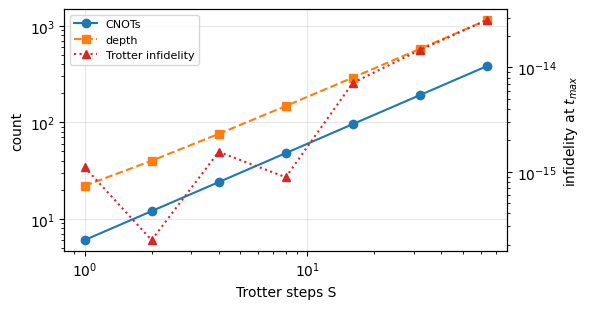

In [14]:
# circuit depth and the number of CNOT gates at each S
rows = []
for s_ in (1, 2, 4, 8, 16, 32, 64):
    cx, depth = cx_count(op, b, times[-1], s_)
    rows.append(dict(S=s_, CNOTs=cx, depth=depth,
                     trotter_infidelity=trotter_infidelity(op, A, b, times[-1], s_)))
cost = pd.DataFrame(rows)
print(cost.to_string(index=False, formatters={"trotter_infidelity": "{:.2e}".format}))

fig, ax1 = plt.subplots(figsize=(6, 3.2))
ax1.loglog(cost.S, cost.CNOTs, "o-", label="CNOTs")
ax1.loglog(cost.S, cost.depth, "s--", label="depth")
ax1.set(xlabel="Trotter steps S", ylabel="count"); ax1.grid(alpha=0.3)
ax2 = ax1.twinx()
ax2.semilogy(cost.S, np.maximum(cost.trotter_infidelity, 1e-16), "^:", color="C3", label="Trotter infidelity")
ax2.set_ylabel("infidelity at $t_{max}$")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8); plt.tight_layout(); plt.savefig("s_analysis.pdf"); plt.show()

### B5. What the circuits should produce: exact probabilities $p(z\mid t_j)$
Before running any circuit, we compute the exact distributions classically. They oscillate strongly in time, so **no single time** shows the full structure. That is why the probabilities are aggregated over $M$ times: $p_{\rm agg}(z)=\frac1M\sum_j p(z\mid t_j)$.

In [15]:
P_exact = np.array(exact_probs(A, b, times))
labels = [format(i, f"0{n}b") for i in range(N)]
df = pd.DataFrame(P_exact, columns=[f"p(|{l}>)" for l in labels]); df.insert(0, "t_j", times)
print(df.round(3).to_string(index=False))
p_agg_exact = P_exact.mean(axis=0)
print("\nexact aggregated p_agg =", p_agg_exact.round(4))

 t_j  p(|00>)  p(|01>)  p(|10>)  p(|11>)
0.25    0.137    0.125    0.343    0.394
0.50    0.069    0.543    0.225    0.163
0.75    0.212    0.323    0.184    0.281
1.00    0.239    0.125    0.575    0.061
1.25    0.213    0.401    0.238    0.148
1.50    0.932    0.043    0.006    0.019
1.75    0.627    0.226    0.052    0.095
2.00    0.119    0.333    0.442    0.105

exact aggregated p_agg = [0.3186 0.265  0.2581 0.1583]


### B6. Step 3: Build the circuits, check the cost and the Trotter accuracy
We show one circuit, count CNOTs for $S=1$ and $S=4$, and compare the Trotterized state with the exact one.

In [16]:
qc = build_evolution_circuit(op, b, times[0], S)
print(transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1, seed_transpiler=1).draw(fold=120))
for s_ in (1, 4):
    cx, depth = cx_count(op, b, times[-1], s_)
    print(f"S={s_}: {cx} CNOTs, depth {depth}, Trotter infidelity at t_max = {trotter_infidelity(op, A, b, times[-1], s_):.2e}")

global phase: 3.4624
           ┌───┐                                            ┌────────┐   ┌────┐  ┌────────┐                      »
   q_0: ───┤ X ├───────────────────────■─────────────────■──┤ Rz(-π) ├───┤ √X ├──┤ Rz(-π) ├──■────────────────■──»
        ┌──┴───┴──┐┌────┐┌──────────┐┌─┴─┐┌───────────┐┌─┴─┐└─┬────┬─┘┌──┴────┴─┐└────────┘┌─┴─┐┌──────────┐┌─┴─┐»
   q_1: ┤ Rz(π/2) ├┤ √X ├┤ Rz(-π/2) ├┤ X ├┤ Rz(0.125) ├┤ X ├──┤ √X ├──┤ Rz(π/2) ├──────────┤ X ├┤ Rz(0.25) ├┤ X ├»
        └─────────┘└────┘└──────────┘└───┘└───────────┘└───┘  └────┘  └─────────┘          └───┘└──────────┘└───┘»
meas: 2/═════════════════════════════════════════════════════════════════════════════════════════════════════════»
                                                                                                                 »
«        ┌─────────┐┌────┐┌────────┐┌───┐┌───────────┐┌───┐┌─────────┐┌────┐┌─────────┐                       »
«   q_0: ┤ Rz(π/2) ├┤ √X ├┤ Rz(-π) ├┤ X ├┤ Rz(0.375) ├┤ X ├┤ R

### B7. Step 4: Sampling on the noiseless simulator
All $M$ circuits run in one batch. We print the counts for each time point, then the pooled counts, and compare the empirical $\hat p_{\rm agg}$ with the exact $p_{\rm agg}$. The standard error of the pooled estimate is $\sigma_z=\big\{\sum_j p(z\mid t_j)[1-p(z\mid t_j)]\big\}^{1/2}/(M\sqrt{N_{\rm shots}})$ (Table II of the paper).

In [17]:
sim = BackendRunner("simulator", seed=42)
circuits = [build_evolution_circuit(op, b, t, S) for t in times]
counts_list = sim.run_batch(circuits, SHOTS)
per_time = np.array([counts_to_array([c], N) for c in counts_list])
df = pd.DataFrame(per_time, columns=[f"|{l}>" for l in labels]); df.insert(0, "t_j", times)
print(df.to_string(index=False))
agg = per_time.sum(axis=0)
p_hat = agg / agg.sum()
print("\npooled counts       :", agg)
print("empirical  p_agg_hat:", p_hat.round(4))
print("exact      p_agg    :", p_agg_exact.round(4))
sigma_z = np.sqrt((P_exact * (1 - P_exact)).sum(0)) / (M * np.sqrt(SHOTS))
print("pooled std errors   :", sigma_z.round(4))

 t_j  |00>  |01>  |10>  |11>
0.25   266   259   699   776
0.50   127  1118   422   333
0.75   393   663   367   577
1.00   484   235  1159   122
1.25   420   781   501   298
1.50  1860    85    11    44
1.75  1266   440   113   181
2.00   235   689   850   226

pooled counts       : [5051 4270 4122 2557]
empirical  p_agg_hat: [0.3157 0.2669 0.2576 0.1598]
exact      p_agg    : [0.3186 0.265  0.2581 0.1583]
pooled std errors   : [0.0029 0.0033 0.0032 0.0027]


### B8. Step 5: Configuration set $\mathcal C$
$\mathcal C$ contains every observed bit string, plus $\mathrm{supp}(b)$, which is always added. If $\mathrm{supp}(b)$ were missing, $b_{\rm sub}$ would be $0$ and so would the solution.

The probability of missing a configuration is at most $\exp(-MN_{\rm shots}\,p_{\rm agg}(z))$.

In [18]:
C = configuration_set(agg, b)
R = len(C)
print("C =", [labels[i] for i in C], "  R =", R, "of N =", N)
print("miss-probability bound per configuration:", np.exp(-M * SHOTS * p_agg_exact))

C = ['00', '01', '10', '11']   R = 4 of N = 4
miss-probability bound per configuration: [0. 0. 0. 0.]


### B9. Step 6: Galerkin projection, solve and lift back
$V=[|z_1\rangle\cdots|z_R\rangle]$ selects the rows and columns of $A$. We solve $A_{\rm sub}x_{\rm sub}=b_{\rm sub}$ and lift back with $x=Vx_{\rm sub}$.

In [19]:
V = np.eye(N)[:, C]                       # N x R isometry
A_sub, b_sub = V.T @ A @ V, V.T @ b
print("A_sub =\n", A_sub, "\nb_sub =", b_sub)
x_sub = np.linalg.solve(A_sub, b_sub)
x_sqd = V @ x_sub
print("x_sub =", x_sub)
print("x_SQD =", x_sqd)
print("x_ref =", x_ref)
print("same as galerkin():", np.allclose(x_sqd, galerkin(A, b, C)))

A_sub =
 [[ 5.  3.  1. -2.]
 [ 3.  5.  2. -1.]
 [ 1.  2.  5. -3.]
 [-2. -1. -3.  5.]] 
b_sub = [0. 0. 0. 1.]
x_sub = [ 0.1939 -0.1394  0.2606  0.4061]
x_SQD = [ 0.1939 -0.1394  0.2606  0.4061]
x_ref = [ 0.1939 -0.1394  0.2606  0.4061]
same as galerkin(): True


### B10. Step 7: Accuracy

In [20]:
m_sim = metrics(A, x_ref, x_sqd)
print(pd.Series(m_sim))

F           1.0
rel_err     0.0
residual    0.0
Anorm       0.0
dtype: float64


### B11. The same pipeline in one call, on the noisy simulator
The noise model has 1 % depolarizing error per CNOT, 0.1 % per single-qubit gate and 2 % readout error. To use a real device's noise instead, write `NoiseModel.from_backend(ibm_service().backend(BACKEND_NAME))`.

Noise shifts the counts but, as long as every configuration is still observed ($R=N$), the solution stays exact. Remark 1 of the paper: adding configurations can never increase the energy-norm error for SPD $A$.

In [21]:
nm = NoiseModel()
nm.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["cx"])
nm.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["sx", "x"])
nm.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.02, 0.98]]))
noisy = BackendRunner("noisy_simulator", noise_model=nm, seed=42)
x_noisy, info_noisy = sqd_solve(A, b, noisy, M=M, dt=dt, shots=SHOTS, trotter_steps=S)
print("noisy counts:", info_noisy["counts"], " R =", info_noisy["R"])
print("noiseless   :", agg)
print(pd.Series(metrics(A, x_ref, x_noisy)))

noisy counts: [4763 4205 4097 2935]  R = 4
noiseless   : [5051 4270 4122 2557]
F           1.0
rel_err     0.0
residual    0.0
Anorm       0.0
dtype: float64


### B12. Truncated subspaces: where the selection actually matters
For large $N$ only $R\ll N$ configurations can be kept. We keep $\mathrm{supp}(b)$ plus the most frequent configurations and compare with the **oracle**, i.e. the $R$ configurations with the largest $|x_z|$, which requires knowing the solution.

In [22]:
rows = []
for R_ in range(1, N + 1):
    C_t = configuration_set(agg, b, max_R=R_)
    rows.append(dict(R=R_, C=[labels[i] for i in C_t],
                     F_SQD=metrics(A, x_ref, galerkin(A, b, C_t))["F"],
                     F_oracle=metrics(A, x_ref, galerkin(A, b, np.argsort(-abs(x_ref))[:R_]))["F"]))
print(pd.DataFrame(rows).round(4).to_string(index=False))

 R                C  F_SQD  F_oracle
 1             [11] 0.5689    0.5689
 2         [00, 11] 0.6957    0.8025
 3     [00, 01, 11] 0.7205    0.9124
 4 [00, 01, 10, 11] 1.0000    1.0000


### B13. Comparison of the sampled distributions

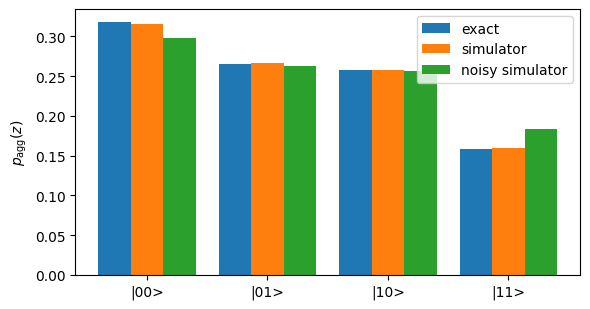

In [23]:
idx = np.arange(N); w = 0.27
plt.figure(figsize=(6, 3.2))
plt.bar(idx - w, p_agg_exact, w, label="exact")
plt.bar(idx, p_hat, w, label="simulator")
plt.bar(idx + w, info_noisy["counts"] / info_noisy["counts"].sum(), w, label="noisy simulator")
plt.xticks(idx, [f"|{l}>" for l in labels]); plt.ylabel(r"$p_{\rm agg}(z)$"); plt.legend(); plt.tight_layout(); plt.show()

### B14. IBM Quantum hardware (optional)
Set `RUN_HARDWARE = True` in the configuration cell and store your API key in the environment variable `IBM_CLOUD_TOKEN`.
The call waits until the job finishes; record the printed job ID. With `RUN_HARDWARE = False` the job of the paper
(`HW_JOB_4x4`) is used through the stored counts.

In [24]:
if RUN_HARDWARE:
    service = ibm_service()
    hw = BackendRunner("hardware", service=service, backend_name=BACKEND_NAME, dynamical_decoupling=True, twirling=True)
    x_hw, info_hw = sqd_solve(A, b, hw, M=M, dt=dt, shots=SHOTS, trotter_steps=S)
    HW_JOB_4x4 = hw.last_job_id
    print("job id:", HW_JOB_4x4, "| counts:", info_hw["counts"], "| R =", info_hw["R"])
    print(pd.Series(metrics(A, x_ref, x_hw)))
else:
    print(f"hardware run skipped (RUN_HARDWARE = False); stored job {HW_JOB_4x4} on {BACKEND_NAME} is used below")

hardware run skipped (RUN_HARDWARE = False); stored job dbh4djsdgr2s73csnj3g on ibm_fez is used below


### B15. Export the hardware counts (run once, needs `IBM_CLOUD_TOKEN`)
Fetches the per-time counts of the finished jobs (no new submission) and stores them in `data/`, so that the
hardware analysis below, and `reproduce_paper.ipynb`, run without an IBM Quantum account.

In [25]:
def fetch_counts_per_time(service, job_id, N_):
    res = service.job(job_id).result()
    return np.array([counts_to_array([res[i].data.meas.get_counts()], N_) for i in range(len(res))])

if "IBM_CLOUD_TOKEN" in os.environ and (RUN_HARDWARE or RUN_HW_SCALING or not os.path.exists(HW_FILE_4x4)
                                         or not os.path.exists(HW_FILE_SCALING)):
    os.makedirs(HW_DATA, exist_ok=True)
    service = ibm_service()
    cnt = fetch_counts_per_time(service, HW_JOB_4x4, N)
    json.dump(dict(job_id=HW_JOB_4x4, backend=BACKEND_NAME, problem="paper_4x4", M=M, dt=dt, S=S, shots=SHOTS,
                   dynamical_decoupling=True, twirling=True, times=times.tolist(), counts_per_time=cnt.tolist()),
              open(HW_FILE_4x4, "w"), indent=1)
    sc = {}
    for N_, job in HW_JOBS_SCALING.items():
        sc[str(N_)] = dict(job_id=job, counts_per_time=fetch_counts_per_time(service, job, N_).tolist())
    json.dump(dict(backend=BACKEND_NAME, problem="screened_poisson", M=8, shots=2000, S=4, jobs=sc),
              open(HW_FILE_SCALING, "w"), indent=1)
    print("hardware counts written to", HW_FILE_4x4, "and", HW_FILE_SCALING)
else:
    print("export skipped:", "files present" if os.path.exists(HW_FILE_4x4) else "IBM_CLOUD_TOKEN not set and no stored counts")

export skipped: IBM_CLOUD_TOKEN not set and no stored counts


data/ibm_fez_4x4_counts.json not found (run B15 once) -> simulators only
       platform  TVD_agg  TVD_mean_per_time     chi2  max_abs_z  R   F
      simulator   0.0033             0.0123   1.6130     0.9873  4 1.0
noisy simulator   0.0251             0.0765 135.5928     9.1650  4 1.0
shot-noise reference: expected TVD_agg ~ 0.0048, chi2 ~ 3 +/- 2.4


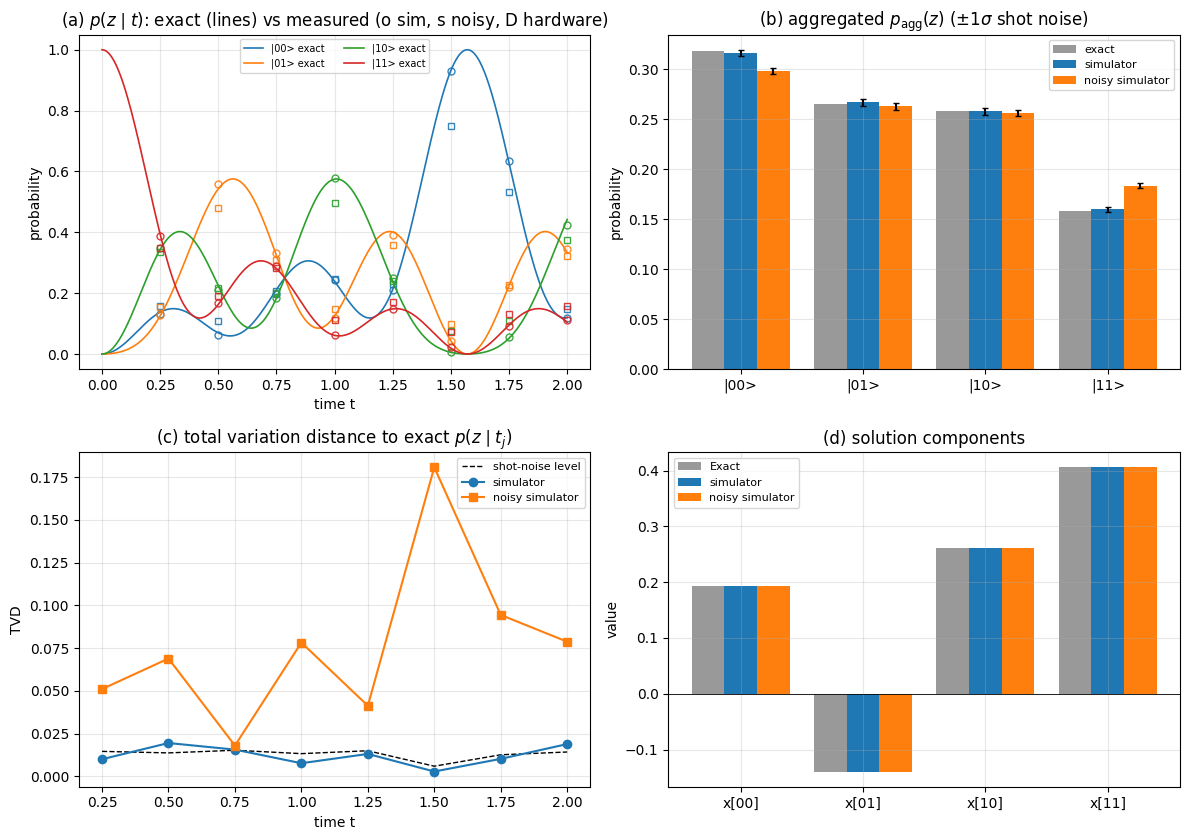

In [26]:
# ===================== IBM hardware vs simulation =====================
# Needs from earlier cells: A, b, op, times, S, SHOTS, x_ref, sim, noisy.
# The hardware counts are read from the stored file (written by B15); no job is submitted.

N = len(b); n = int(np.log2(N)); M = len(times)
labels = [format(i, f"0{n}b") for i in range(N)]

def per_time_counts(runner):
    """Run the M circuits on a simulator runner; return an (M, N) array of counts."""
    circs = [build_evolution_circuit(op, b, t, S) for t in times]
    return np.array([counts_to_array([c], N) for c in runner.run_batch(circs, SHOTS)])


P_ex = np.array(exact_probs(A, b, times))                      # exact p(z|t_j), shape (M, N)
platforms = {"simulator": per_time_counts(sim),
             "noisy simulator": per_time_counts(noisy)}
if os.path.exists(HW_FILE_4x4):
    platforms["IBM hardware"] = np.array(json.load(open(HW_FILE_4x4))["counts_per_time"])
else:
    print(f"{HW_FILE_4x4} not found (run B15 once) -> simulators only")

# ---- statistics per platform ----
var_agg = (P_ex * (1 - P_ex)).sum(0) / (M**2 * SHOTS)          # variance of pooled frequency
rows = []
for name, cnt in platforms.items():
    P_hat = cnt / cnt.sum(1, keepdims=True)                     # empirical p(z|t_j)
    p_hat = cnt.sum(0) / cnt.sum()                              # empirical p_agg
    z = (p_hat - P_ex.mean(0)) / np.sqrt(var_agg)
    x_plat = galerkin(A, b, configuration_set(cnt.sum(0), b))
    rows.append(dict(platform=name,
                     TVD_agg=0.5 * np.abs(p_hat - P_ex.mean(0)).sum(),
                     TVD_mean_per_time=np.mean(0.5 * np.abs(P_hat - P_ex).sum(1)),
                     chi2=float((z**2).sum()), max_abs_z=float(np.abs(z).max()),
                     R=len(configuration_set(cnt.sum(0), b)), **{"F": metrics(A, x_ref, x_plat)["F"]}))
stats = pd.DataFrame(rows)
print(stats.round(4).to_string(index=False))
print(f"shot-noise reference: expected TVD_agg ~ {0.5*np.sqrt(2/np.pi)*np.sqrt(var_agg).sum():.4f}, "
      f"chi2 ~ {N-1} +/- {np.sqrt(2*(N-1)):.1f}")

# ---- figure ----
colors = plt.cm.tab10(np.arange(N))
mk = {"simulator": "o", "noisy simulator": "s", "IBM hardware": "D"}
fig, ax = plt.subplots(2, 2, figsize=(12, 8.5))

# (a) time-resolved probabilities: exact curves, measured points
tt = np.linspace(0, times[-1], 400)
P_fine = np.array(exact_probs(A, b, tt[1:])); P_fine = np.vstack([np.eye(N)[np.argmax(np.abs(b))], P_fine])
for k in range(N):
    ax[0, 0].plot(tt, P_fine[:, k], color=colors[k], lw=1.2, label=f"|{labels[k]}> exact")
    for name, cnt in platforms.items():
        ax[0, 0].plot(times, cnt[:, k] / cnt.sum(1), mk[name], color=colors[k], ms=5,
                      mfc="none" if name != "IBM hardware" else colors[k], alpha=0.9)
ax[0, 0].set(title=r"(a) $p(z\mid t)$: exact (lines) vs measured (o sim, s noisy, D hardware)",
             xlabel="time t", ylabel="probability")
ax[0, 0].legend(fontsize=7, ncol=2)

# (b) aggregated distribution with shot-noise error bars
w = 0.8 / (len(platforms) + 1); idx = np.arange(N)
ax[0, 1].bar(idx - 0.4 + w/2, P_ex.mean(0), w, color="0.6", label="exact")
for i, (name, cnt) in enumerate(platforms.items(), start=1):
    p_hat = cnt.sum(0) / cnt.sum()
    ax[0, 1].bar(idx - 0.4 + w/2 + i*w, p_hat, w, yerr=np.sqrt(var_agg), capsize=2, label=name)
ax[0, 1].set_xticks(idx, [f"|{l}>" for l in labels])
ax[0, 1].set(title=r"(b) aggregated $p_{\rm agg}(z)$ ($\pm1\sigma$ shot noise)", ylabel="probability")
ax[0, 1].legend(fontsize=8)

# (c) distance to the exact distribution at each time
sn = [0.5*np.sqrt(2/np.pi)*np.sqrt(P_ex[j]*(1-P_ex[j])/SHOTS).sum() for j in range(M)]
ax[1, 0].plot(times, sn, "k--", lw=1, label="shot-noise level")
for name, cnt in platforms.items():
    P_hat = cnt / cnt.sum(1, keepdims=True)
    ax[1, 0].plot(times, 0.5*np.abs(P_hat - P_ex).sum(1), mk[name] + "-", label=name)
ax[1, 0].set(title=r"(c) total variation distance to exact $p(z\mid t_j)$", xlabel="time t", ylabel="TVD")
ax[1, 0].legend(fontsize=8)

# (d) recovered solution
ax[1, 1].bar(idx - 0.4 + w/2, x_ref, w, color="0.6", label="Exact")
for i, (name, cnt) in enumerate(platforms.items(), start=1):
    ax[1, 1].bar(idx - 0.4 + w/2 + i*w, galerkin(A, b, configuration_set(cnt.sum(0), b)), w, label=name)
ax[1, 1].axhline(0, color="k", lw=0.6)
ax[1, 1].set_xticks(idx, [f"x[{l}]" for l in labels])
ax[1, 1].set(title="(d) solution components", ylabel="value"); ax[1, 1].legend(fontsize=8)

for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("hardware_vs_simulation.pdf"); plt.show()

---
# Part C: Scalability test, $N = 4, 8, 16, 32, 64, 128, \dots$

**Two matrix families**, both with a point source $b=|z_0\rangle$, which needs only X gates to prepare:
* **banded**: screened Poisson, a tridiagonal matrix with $2.5$ on the diagonal and $-1$ off the diagonal. The solution is localized around the source. In the Pauli basis it needs $L=N$ terms.
* **dense**: $QQ^\top+N\mathbb I$ with $Q_{ij}\sim U[0,1)$. It needs $L\approx N(N+1)/2$ Pauli terms.

**Three execution modes**
* `simulator`: real Trotter circuits on the noiseless Aer simulator.
* `noisy_simulator`: the same circuits with the noise model of B11. This is slow for deep circuits, so it is limited to small $N$.
* `exact-emulation`: samples from the exact $e^{-iAt}$, with no circuits and no Trotter error. It shows how the *selection* scales to large $N$.

**Settings for each size**
* $\Delta t=\pi/(\text{Gershgorin bound})$, $M=8$, 2000 shots per time point.
* Trotter steps $S$ are chosen **adaptively**: the smallest power of two for which the Trotter infidelity at $t_{\max}$ is below `TROTTER_TOL`, capped at `S_MAX`.

**Columns of the results table**
* $L$: number of Pauli terms.
* $S$ and the Trotter infidelity.
* CNOTs per circuit.
* $R$ and $R/N$: size of the untruncated configuration set.
* $F$, the relative error and the energy-norm error of the untruncated solution.
* $F$ after truncation to $R_{\rm trunc}=\max(2,N/8)$, for SQD and for the oracle.
* Wall time.

In [27]:
# ---- configuration of the scalability test (edit freely) ----
SCAL_M, SCAL_SHOTS = 8, 2000
TROTTER_TOL, S_MAX = 1e-2, 64
PLAN = [  # (family, sizes N, mode)
    ("banded", [4, 8, 16, 32, 64, 128],                 "simulator"),
    ("banded", [4, 8, 16],                              "noisy_simulator"),
    ("banded", [4, 8, 16, 32, 64, 128, 256, 512, 1024], "exact-emulation"),
    ("dense",  [4, 8, 16, 32],                          "simulator"),
    ("dense",  [4, 8],                                  "noisy_simulator"),
    ("dense",  [4, 8, 16, 32, 64, 128, 256],            "exact-emulation"),
]

In [28]:
def choose_trotter_steps(op, A, b, t_max, tol=TROTTER_TOL, s_max=S_MAX):
    """Smallest S = 1, 2, 4, ... with Trotter infidelity < tol at t_max (capped at s_max)."""
    S_ = 1
    while True:
        inf = trotter_infidelity(op, A, b, t_max, S_)
        if inf < tol or S_ >= s_max:
            return S_, inf
        S_ *= 2

def make_problem(family, N):
    return screened_poisson(N) if family == "banded" else random_spd(N)

def run_case(family, N, mode, seed=0):
    A_, b_ = make_problem(family, N)
    x_ref_ = np.linalg.solve(A_.toarray() if sp.issparse(A_) else A_, b_)
    dt_ = np.pi / spectral_width_bound(A_)                      # Nyquist step from Gershgorin
    times_ = dt_ * np.arange(1, SCAL_M + 1)
    row = dict(family=family, N=N, n=int(np.log2(N)), mode=mode)
    t0 = time.time()
    if mode == "exact-emulation":
        counts = sample_exact(A_, b_, times_, SCAL_SHOTS, seed)
        row.update(L=np.nan, S=np.nan, trotter_inf=0.0, cx_per_circuit=np.nan)
    else:
        op_ = pauli_op(A_)
        S_, inf = choose_trotter_steps(op_, A_, b_, times_[-1])
        cx, _ = cx_count(op_, b_, times_[-1], S_)
        runner = (BackendRunner("simulator", seed=seed) if mode == "simulator"
                  else BackendRunner("noisy_simulator", noise_model=nm, seed=seed))
        counts = sample_configurations(op_, b_, times_, SCAL_SHOTS, S_, runner)
        row.update(L=len(op_), S=S_, trotter_inf=inf, cx_per_circuit=cx)
    C_ = configuration_set(counts, b_)
    m = metrics(A_, x_ref_, galerkin(A_, b_, C_))
    R_tr = max(2, N // 8)
    F_tr = metrics(A_, x_ref_, galerkin(A_, b_, configuration_set(counts, b_, max_R=R_tr)))["F"]
    F_or = metrics(A_, x_ref_, galerkin(A_, b_, np.argsort(-np.abs(x_ref_))[:R_tr]))["F"]
    row.update(R=len(C_), R_over_N=len(C_) / N, F=m["F"], rel_err=m["rel_err"], A_norm_err=m["Anorm"],
               R_trunc=R_tr, F_trunc_SQD=F_tr, F_trunc_oracle=F_or, seconds=round(time.time() - t0, 1))
    return row

In [29]:
results = []
for family, sizes, mode in PLAN:
    for N_ in sizes:
        r = run_case(family, N_, mode)
        results.append(r)
        print(f"{family:6s} {mode:16s} N={N_:5d}  L={r['L']!s:>5}  S={r['S']!s:>4}  CX={r['cx_per_circuit']!s:>7}  "
              f"R={r['R']:4d}  F={r['F']:.6f}  F_trunc={r['F_trunc_SQD']:.3f} (oracle {r['F_trunc_oracle']:.3f})  {r['seconds']} s",
              flush=True)
scal = pd.DataFrame(results)

banded simulator        N=    4  L=    4  S=  32  CX=    128  R=   4  F=1.000000  F_trunc=0.859 (oracle 0.859)  0.1 s
banded simulator        N=    8  L=    8  S=  64  CX=   1280  R=   8  F=1.000000  F_trunc=0.759 (oracle 0.759)  0.5 s
banded simulator        N=   16  L=   16  S=  32  CX=   1920  R=  16  F=1.000000  F_trunc=0.600 (oracle 0.745)  0.8 s
banded simulator        N=   32  L=   32  S=  64  CX=   9472  R=  32  F=1.000000  F_trunc=0.931 (oracle 0.931)  3.7 s
banded simulator        N=   64  L=   64  S=  64  CX=  21248  R=  32  F=1.000000  F_trunc=0.995 (oracle 0.995)  9.5 s
banded simulator        N=  128  L=  128  S=  64  CX=  45312  R=  32  F=1.000000  F_trunc=1.000 (oracle 1.000)  22.3 s
banded noisy_simulator  N=    4  L=    4  S=  32  CX=    128  R=   4  F=1.000000  F_trunc=0.859 (oracle 0.859)  0.2 s
banded noisy_simulator  N=    8  L=    8  S=  64  CX=   1280  R=   8  F=1.000000  F_trunc=0.612 (oracle 0.759)  0.9 s
banded noisy_simulator  N=   16  L=   16  S=  32  CX=  

### C1. Results table

In [30]:
cols = ["family", "mode", "N", "n", "L", "S", "trotter_inf", "cx_per_circuit", "R", "R_over_N",
        "F", "rel_err", "A_norm_err", "R_trunc", "F_trunc_SQD", "F_trunc_oracle", "seconds"]
display(scal[cols].style.format({"trotter_inf": "{:.1e}", "R_over_N": "{:.3f}", "F": "{:.6f}", "rel_err": "{:.1e}",
                                 "A_norm_err": "{:.1e}", "F_trunc_SQD": "{:.3f}", "F_trunc_oracle": "{:.3f}",
                                 "L": "{:.0f}", "S": "{:.0f}", "cx_per_circuit": "{:.0f}"}, na_rep="-"))
scal.to_csv("sqd_scalability_results.csv", index=False)
print("saved to sqd_scalability_results.csv")

,family,mode,N,n,L,S,trotter_inf,cx_per_circuit,R,R_over_N,F,rel_err,A_norm_err,R_trunc,F_trunc_SQD,F_trunc_oracle,seconds
0,banded,simulator,4,2,4,32,3.6e-03,128,4,1.000,1.000000,0.0e+00,0.0e+00,2,0.859,0.859,0.100000
1,banded,simulator,8,3,8,64,3.4e-03,1280,8,1.000,1.000000,0.0e+00,0.0e+00,2,0.759,0.759,0.500000
2,banded,simulator,16,4,16,32,9.5e-03,1920,16,1.000,1.000000,0.0e+00,0.0e+00,2,0.600,0.745,0.800000
3,banded,simulator,32,5,32,64,2.5e-03,9472,32,1.000,1.000000,0.0e+00,0.0e+00,4,0.931,0.931,3.700000
4,banded,simulator,64,6,64,64,2.5e-03,21248,32,0.500,1.000000,1.7e-05,1.7e-05,8,0.995,0.995,9.500000
5,banded,simulator,128,7,128,64,2.5e-03,45312,32,0.250,1.000000,1.7e-05,1.7e-05,16,1.000,1.000,22.300000
6,banded,noisy_simulator,4,2,4,32,3.6e-03,128,4,1.000,1.000000,0.0e+00,0.0e+00,2,0.859,0.859,0.200000
7,banded,noisy_simulator,8,3,8,64,3.4e-03,1280,8,1.000,1.000000,0.0e+00,0.0e+00,2,0.612,0.759,0.900000
8,banded,noisy_simulator,16,4,16,32,9.5e-03,1920,16,1.000,1.000000,0.0e+00,0.0e+00,2,0.745,0.745,1.400000
9,banded,exact-emulation,4,2,-,-,0.0e+00,-,4,1.000,1.000000,0.0e+00,0.0e+00,2,0.859,0.859,0.000000


saved to sqd_scalability_results.csv


### C2. Plots
* **(a)** circuit cost: Pauli terms $L$ and CNOTs per circuit against $N$;
* **(b)** relative size of the configuration set, $R/N$;
* **(c)** accuracy of the untruncated solution;
* **(d)** quality of the truncated selection, SQD against the oracle.

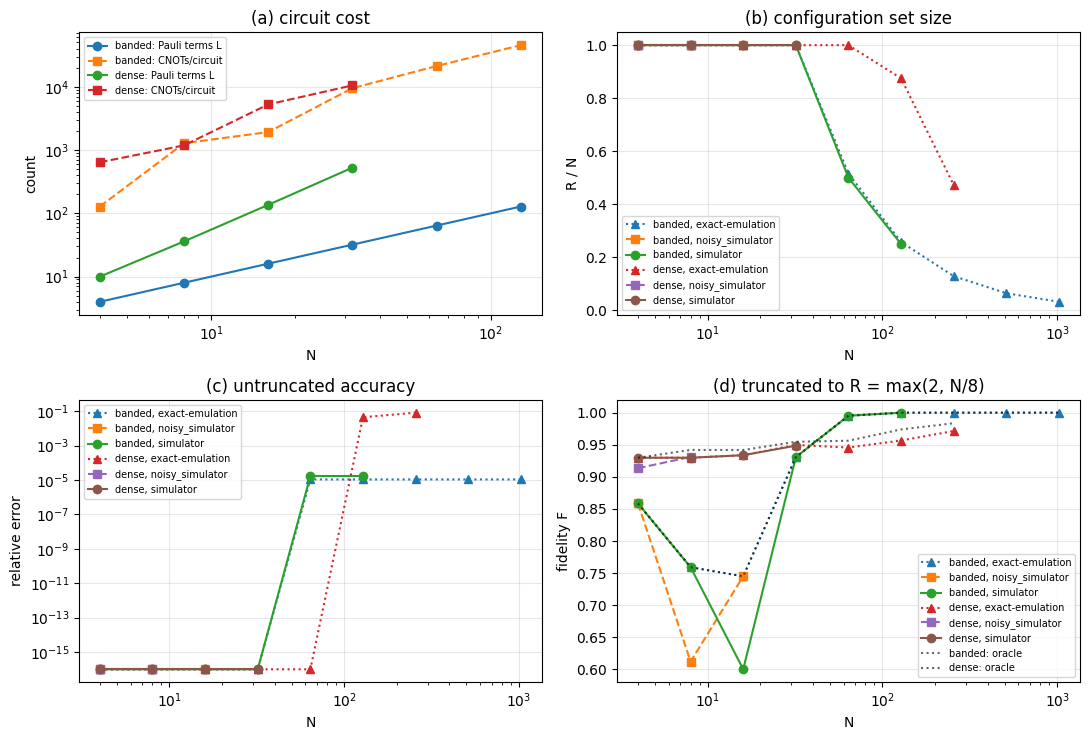

In [31]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
mk = {"simulator": "o-", "noisy_simulator": "s--", "exact-emulation": "^:"}
for (fam, mode), g in scal.groupby(["family", "mode"]):
    lab = f"{fam}, {mode}"
    if mode == "simulator":
        ax[0, 0].loglog(g.N, g.L, "o-", label=f"{fam}: Pauli terms L")
        ax[0, 0].loglog(g.N, g.cx_per_circuit, "s--", label=f"{fam}: CNOTs/circuit")
    ax[0, 1].semilogx(g.N, g.R_over_N, mk[mode], label=lab)
    ax[1, 0].loglog(g.N, np.maximum(g.rel_err, 1e-16), mk[mode], label=lab)
    ax[1, 1].semilogx(g.N, g.F_trunc_SQD, mk[mode], label=lab)
for fam, g in scal[scal["mode"] == "exact-emulation"].groupby("family"):
    ax[1, 1].semilogx(g.N, g.F_trunc_oracle, "k:", alpha=0.6, label=f"{fam}: oracle")
ax[0, 0].set(title="(a) circuit cost", xlabel="N", ylabel="count")
ax[0, 1].set(title="(b) configuration set size", xlabel="N", ylabel="R / N")
ax[1, 0].set(title="(c) untruncated accuracy", xlabel="N", ylabel="relative error")
ax[1, 1].set(title="(d) truncated to R = max(2, N/8)", xlabel="N", ylabel="fidelity F")
for a in ax.ravel():
    a.grid(alpha=0.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("scalability.pdf", bbox_inches="tight"); plt.show()

### C3. Scalability on IBM hardware (optional)
With `RUN_HW_SCALING = True` this runs the banded family on hardware for the sizes in `HW_SIZES`; otherwise the stored jobs `HW_JOBS_SCALING` are used.

The circuits become deep quickly; see the CNOT column above. In practice, cap the number of Trotter steps (`HW_S_MAX`) and accept some Trotter error. Each size is one batched job.

In [32]:
HW_SIZES, HW_S_MAX = [4, 8, 16], 4
hw_rows, hw_counts = [], {}
if RUN_HW_SCALING:
    service = ibm_service()
    hw = BackendRunner("hardware", service=service, backend_name=BACKEND_NAME, dynamical_decoupling=True, twirling=True)
elif os.path.exists(HW_FILE_SCALING):
    stored = json.load(open(HW_FILE_SCALING))["jobs"]
for N_ in HW_SIZES:
    if not RUN_HW_SCALING and not os.path.exists(HW_FILE_SCALING):
        break
    A_, b_ = make_problem("banded", N_); x_ref_ = np.linalg.solve(A_.toarray(), b_)
    op_ = pauli_op(A_); dt_ = np.pi / spectral_width_bound(A_); t_ = dt_ * np.arange(1, SCAL_M + 1)
    S_, inf = choose_trotter_steps(op_, A_, b_, t_[-1], s_max=HW_S_MAX)
    if RUN_HW_SCALING:
        counts = sample_configurations(op_, b_, t_, SCAL_SHOTS, S_, hw); job = hw.last_job_id
    else:
        cpt = np.array(stored[str(N_)]["counts_per_time"]); counts = cpt.sum(0); job = stored[str(N_)]["job_id"]
        hw_counts[N_] = cpt
    C_ = configuration_set(counts, b_); m = metrics(A_, x_ref_, galerkin(A_, b_, C_))
    R_tr = max(2, N_ // 8)
    hw_rows.append(dict(N=N_, S=S_, trotter_inf=inf, job=job, R=len(C_), F=m["F"], rel_err=m["rel_err"],
                        F_trunc=metrics(A_, x_ref_, galerkin(A_, b_, configuration_set(counts, b_, max_R=R_tr)))["F"]))
if hw_rows:
    display(pd.DataFrame(hw_rows))
else:
    print(f"hardware scaling skipped: RUN_HW_SCALING = False and {HW_FILE_SCALING} not found (run B15 once)")

hardware scaling skipped: RUN_HW_SCALING = False and data/ibm_fez_banded_scaling_counts.json not found (run B15 once)


### C4. How to read the results
* **Circuit cost (a).**
  * For the banded family $L=N$, so the CNOT count per Trotter step roughly doubles with every added qubit.
  * For the dense family $L\approx N^2/2$.
  * Keeping the Trotter error below 1 % needs tens of Trotter steps, so circuits reach $10^4$ CNOTs or more already at $N=32$–$64$. This is the main obstacle to running on hardware.
* **Configuration set (b).** In the untruncated set, $R/N$ falls for the banded family once $N$ exceeds the light cone of the time window: about 33 configurations for $t_{\max}=2\pi$, independent of $N$. That is the regime where SQD compresses the problem. For small $N$, or when Trotter or noise errors spread amplitude, $R=N$ and the "quantum" subspace is simply the full space.
* **Accuracy (c).** With $R=N$ the solution is exact. With $R<N$ the error is set by the amplitude of the solution outside the light cone, which is $\sim10^{-5}$ for the banded family.
* **Truncation (d).** When $R$ must be cut to $R\ll N$, the frequency-ranked selection should be compared with the oracle. Where SQD falls below the oracle, selection by sampling frequency is not targeted at the solution (Remark 2 of the paper).
* **Noise.** Noise mostly *adds* configurations. Untruncated SPD solutions do not degrade (Remark 1 of the paper), but the compression is lost, and truncated selections can degrade.

In [33]:
if not hw_rows:
    print("no hardware-scaling data: cell skipped")
else:
    # ===================== Hardware scaling: plots and comparison =====================
    # Uses hw_rows and hw_counts (from the hardware-scaling cell), nm, and the notebook functions.
    # Hardware jobs are NOT re-run: per-time counts come from the stored file (or from the jobs just run).
    # Reference runs use the SAME circuits (same S) on the noiseless and noisy simulators.

    def ideal_trotter_probs(op_, b_, t, S_):
        """Exact output distribution of the Trotterized circuit (no shot noise, no hardware noise)."""
        qc = transpile(build_evolution_circuit(op_, b_, t, S_, measure=False),
                       basis_gates=["cx", "rz", "sx", "x"], optimization_level=0)
        return np.abs(Statevector(qc).data) ** 2

    def hw_counts_per_time(job_id, N_):
        if N_ in hw_counts:
            return hw_counts[N_]
        res = ibm_service().job(job_id).result()
        return np.array([counts_to_array([res[i].data.meas.get_counts()], N_) for i in range(len(res))])

    def two_qubit_count(op_, b_, t, S_):
        if "hw" not in globals():
            return "n/a (needs the backend)"
        tq = transpile(build_evolution_circuit(op_, b_, t, S_), hw.backend, optimization_level=hw.optimization_level)
        ops = tq.count_ops(); return sum(ops.get(g, 0) for g in ("cz", "ecr", "cx"))

    def tvd(p, q): return 0.5 * np.abs(p - q).sum()

    cmp_rows, dists = [], {}
    noisy_ref = BackendRunner("noisy_simulator", noise_model=nm, seed=1)
    sim_ref = BackendRunner("simulator", seed=1)
    for row in hw_rows:
        N_, S_ = row["N"], row["S"]
        A_, b_ = make_problem("banded", N_); x_ref_ = np.linalg.solve(A_.toarray(), b_)
        op_ = pauli_op(A_); t_ = np.pi / spectral_width_bound(A_) * np.arange(1, SCAL_M + 1)
        P_exact = np.array(exact_probs(A_, b_, t_))                      # exact propagator
        P_trot = np.array([ideal_trotter_probs(op_, b_, t, S_) for t in t_])  # ideal Trotter circuit
        runs = {"IBM hardware": hw_counts_per_time(row["job"], N_)}
        circs = [build_evolution_circuit(op_, b_, t, S_) for t in t_]
        runs["simulator (same S)"] = np.array([counts_to_array([c], N_) for c in sim_ref.run_batch(circs, SCAL_SHOTS)])
        runs["noisy simulator (same S)"] = np.array([counts_to_array([c], N_) for c in noisy_ref.run_batch(circs, SCAL_SHOTS)])
        R_tr = max(2, N_ // 8)
        F_or = metrics(A_, x_ref_, galerkin(A_, b_, np.argsort(-np.abs(x_ref_))[:R_tr]))["F"]
        # support of the exact propagator above the shot threshold (what an ideal sampler would find)
        R_exact = int(np.sum(P_exact.mean(0) > 1 / (SCAL_M * SCAL_SHOTS)) )
        shot_tvd = 0.5 * np.sqrt(2 / np.pi) * np.sqrt(P_trot.mean(0) * (1 - P_trot.mean(0)) / (SCAL_M * SCAL_SHOTS)).sum()
        for name, cnt in runs.items():
            agg = cnt.sum(0); p_hat = agg / agg.sum()
            C_ = configuration_set(agg, b_); m = metrics(A_, x_ref_, galerkin(A_, b_, C_))
            cmp_rows.append(dict(N=N_, platform=name, S=S_, trotter_inf=row["trotter_inf"],
                                 R=len(C_), R_over_N=len(C_) / N_, F=m["F"], rel_err=m["rel_err"],
                                 F_trunc=metrics(A_, x_ref_, galerkin(A_, b_, configuration_set(agg, b_, max_R=R_tr)))["F"],
                                 F_oracle=F_or, R_exact=R_exact,
                                 TVD_vs_ideal_trotter=tvd(p_hat, P_trot.mean(0)),
                                 TVD_vs_exact=tvd(p_hat, P_exact.mean(0)), shot_noise_TVD=shot_tvd))
            dists[(N_, name)] = p_hat
        dists[(N_, "ideal Trotter")] = P_trot.mean(0); dists[(N_, "exact")] = P_exact.mean(0)
        print(f"N={N_}: 2-qubit gates per circuit on {BACKEND_NAME} = {two_qubit_count(op_, b_, t_[-1], S_)}")

    cmp = pd.DataFrame(cmp_rows)
    display(cmp.round(4))
    cmp.to_csv("hw_scaling_comparison.csv", index=False)

    # ---------------- figure ----------------
    plats = ["simulator (same S)", "noisy simulator (same S)", "IBM hardware"]
    style = {"simulator (same S)": ("o-", "C0"), "noisy simulator (same S)": ("s--", "C1"), "IBM hardware": ("D-", "C3")}
    Ns = sorted(cmp.N.unique())
    fig, ax = plt.subplots(2, 2, figsize=(12, 8.5))
    for p in plats:
        g = cmp[cmp.platform == p].sort_values("N"); st, c = style[p]
        ax[0, 0].plot(g.N, g.R_over_N, st, color=c, label=p)
        ax[0, 1].plot(g.N, g.TVD_vs_ideal_trotter, st, color=c, label=p)
        ax[1, 0].plot(g.N, g.F_trunc, st, color=c, label=p)
    g0 = cmp[cmp.platform == plats[0]].sort_values("N")
    ax[0, 0].plot(g0.N, g0.R_exact / g0.N, "k:", label="exact propagator (above shot threshold)")
    ax[0, 1].plot(g0.N, g0.shot_noise_TVD, "k:", label="shot-noise level")
    ax[1, 0].plot(g0.N, g0.F_oracle, "k:", label="oracle")
    ax[0, 0].set(title="(a) configuration-set size", xlabel="N", ylabel="R / N", ylim=(0, 1.05))
    ax[0, 1].set(title=r"(b) TVD of $\hat p_{\rm agg}$ to the ideal Trotter circuit", xlabel="N", ylabel="TVD")
    ax[1, 0].set(title=r"(c) fidelity after truncation to $R=\max(2,N/8)$", xlabel="N", ylabel="F")
    # (d) aggregated distributions: hardware vs ideal Trotter vs exact, one row per N (offset)
    for k, N_ in enumerate(Ns):
        z = np.arange(N_) / N_ + k            # map configurations of each size onto [k, k+1)
        ax[1, 1].step(z, dists[(N_, "exact")], where="mid", color="0.5", lw=1, label="exact propagator" if k == 0 else None)
        ax[1, 1].step(z, dists[(N_, "ideal Trotter")], where="mid", color="C0", lw=1, label="ideal Trotter circuit" if k == 0 else None)
        ax[1, 1].plot(z, dists[(N_, "IBM hardware")], "D", color="C3", ms=3, label="IBM hardware" if k == 0 else None)
        if k: ax[1, 1].axvline(k, color="0.8", lw=0.8)
    ax[1, 1].set_xticks([k + 0.5 for k in range(len(Ns))], [f"N={N_}" for N_ in Ns])
    ax[1, 1].set(title=r"(d) aggregated distribution $p_{\rm agg}(z)$ (z ordered within each block)", ylabel="probability")
    for a in ax.ravel():
        a.grid(alpha=0.3); a.legend(fontsize=7)
    for a in (ax[0, 0], ax[0, 1], ax[1, 0]):
        a.set_xscale("log", base=2); a.set_xticks(Ns, [str(v) for v in Ns])
    plt.suptitle(f"SQD on {BACKEND_NAME}: banded problem, M={SCAL_M}, {SCAL_SHOTS} shots/time, S capped at {HW_S_MAX}", fontsize=11)
    plt.tight_layout(); plt.savefig("hw_scaling.pdf"); plt.show()

no hardware-scaling data: cell skipped


---
# Part D: Localized problem, $N=1024$ (Sec. IV B and IV F of the paper)
Screened Poisson operator $A=-\Delta_h+0.5\,\mathbb I$ with a point source at $z_0=N/2$, $\Delta t=\pi/4$ (Gershgorin), $M=8$,
2000 shots per time point. Sampling uses the exact distributions $p(z\mid t_j)$ (no circuits, no Trotter error); the
circuit runs of the same problem are in Part C.
* **D1** untruncated configuration set (seed 0); **D2** spread over 30 seeds and a 4× longer time window;
* **D3** truncated subspaces: SQD against the oracle, classical greedy selection and random selection (Table V);
* **D4** classical Krylov support and conjugate gradients (Sec. IV F).

In [34]:
# ===================== Part D: localized problem (banded, N = 1024) =====================
# Reproduces the "Localized problems" subsection of the paper with the functions defined above.
# Sampling is from the exact distributions p(z|t_j) (no circuits, no Trotter error); circuits are in Part C.
N_LOC, MU, M_LOC, SHOTS_LOC = 1024, 0.5, 8, 2000
N_SEEDS, N_RAND = 30, 1000                      # seeds for the spread, random sets per R

A_loc, b_loc = screened_poisson(N_LOC, MU)       # tridiagonal 2+mu / -1, point source at N/2
z0 = int(np.flatnonzero(b_loc)[0])
x_loc = spla.spsolve(A_loc.tocsc(), b_loc)
bound = spectral_width_bound(A_loc)              # Gershgorin
ev = np.linalg.eigvalsh(A_loc.toarray())
dt_loc = np.pi / bound
print(f"N={N_LOC}  source z0={z0}  Gershgorin width bound={bound:.5f}  true width={ev[-1]-ev[0]:.5f}")
print(f"dt=pi/bound={dt_loc:.4f}  t_max={M_LOC*dt_loc:.4f}  participation ratio={1/np.sum((x_loc/np.linalg.norm(x_loc))**4):.3f}")

def times_for(M_):  return dt_loc * np.arange(1, M_ + 1)
def run_exact(seed, M_=M_LOC):  return sample_exact(A_loc, b_loc, times_for(M_), SHOTS_LOC, seed)
def Fof(C):  return metrics(A_loc, x_loc, galerkin(A_loc, b_loc, C))["F"]

# ---- D1. Untruncated configuration set (notebook seed 0) ----
print("\n--- D1. untruncated, M = 8, seed 0 ---")
counts0 = run_exact(0)
C0 = configuration_set(counts0, b_loc)
m0 = metrics(A_loc, x_loc, galerkin(A_loc, b_loc, C0))
print(f"R={len(C0)} of {N_LOC}  window=[{C0.min()}, {C0.max()}]  1-F={1-m0['F']:.2e}  "
      f"rel_err={m0['rel_err']:.2e}  energy-norm err={m0['Anorm']:.2e}")

# ---- D2. Seed spread, and a 4x longer time window ----
print("\n--- D2. spread over seeds ---")
rows = []
for M_ in (8, 32):
    R_, e_ = [], []
    for s in range(N_SEEDS):
        C_ = configuration_set(run_exact(s, M_), b_loc)
        R_.append(len(C_)); e_.append(metrics(A_loc, x_loc, galerkin(A_loc, b_loc, C_))["rel_err"])
    c_ = configuration_set(run_exact(0, M_), b_loc)
    rows.append(dict(M=M_, t_max=round(M_*dt_loc, 2), R_seed0=len(c_), R_min=min(R_), R_median=np.median(R_), R_max=max(R_),
                     err_seed0=metrics(A_loc, x_loc, galerkin(A_loc, b_loc, c_))["rel_err"], err_min=min(e_), err_max=max(e_)))
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

# ---- D3. Truncated subspaces: SQD vs oracle vs classical greedy vs random ----
def greedy(R):
    """Classical residual-based selection: start from supp(b), add the configuration with the largest |b - A x|_z."""
    C = [z0]
    while len(C) < R:
        r = np.abs(b_loc - A_loc @ galerkin(A_loc, b_loc, C)); r[C] = -1; C.append(int(np.argmax(r)))
    return C

rng = np.random.default_rng(1)
order = [int(i) for i in np.argsort(-counts0, kind="stable") if counts0[i] > 0]       # sampled configs, most frequent first
others = np.delete(np.arange(N_LOC), z0)
rows = []
for R in (2, 4, 8, 16, 32):
    rows.append(dict(
        R=R,
        SQD=Fof(configuration_set(counts0, b_loc, max_R=R)),                        # supp(b) + most frequent
        SQD_without_supp_b=Fof(np.array(order[:R])),                                 # most frequent only
        oracle=Fof(np.argsort(-np.abs(x_loc))[:R]),                                  # R largest |x_z| (needs the solution)
        greedy=Fof(greedy(R)),
        random_with_source=np.mean([Fof(np.r_[z0, rng.choice(others, R-1, replace=False)]) for _ in range(N_RAND)]),
        random_without_source=np.mean([Fof(rng.choice(N_LOC, R, replace=False)) for _ in range(N_RAND)])))
print("\n--- D3. fidelity of truncated subspaces (N = 1024, seed 0) ---")
tab = pd.DataFrame(rows); tab["1-SQD"] = 1 - tab["SQD"]
print(tab.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
tab.to_csv("sqd_localized_truncation.csv", index=False)

# ---- D4. Is the quantum step necessary? classical Krylov support and conjugate gradients ----
print("\n--- D4. classical comparison ---")
v, S_kr = b_loc.copy(), {z0}
for _ in range(16):
    v = A_loc @ v; S_kr |= set(np.flatnonzero(np.abs(v) > 0))
print(f"classical Krylov support (16 mat-vecs): {len(S_kr)} configs; equals sampled set: {S_kr == set(C0.tolist())}; "
      f"F(Krylov)={Fof(np.array(sorted(S_kr))):.10f}  F(sampled)={m0['F']:.10f}")
res = []
spla.cg(A_loc, b_loc, rtol=1e-10, callback=lambda xk: res.append(np.linalg.norm(A_loc @ xk - b_loc) / np.linalg.norm(b_loc)))
print(f"conjugate gradients: {len(res)} iterations to residual {res[-1]:.1e}")

N=1024  source z0=512  Gershgorin width bound=4.00000  true width=3.99998
dt=pi/bound=0.7854  t_max=6.2832  participation ratio=2.451

--- D1. untruncated, M = 8, seed 0 ---
R=33 of 1024  window=[496, 528]  1-F=1.16e-10  rel_err=1.08e-05  energy-norm err=1.08e-05

--- D2. spread over seeds ---
 M  t_max  R_seed0  R_min  R_median  R_max  err_seed0   err_min   err_max
 8   6.28       33     31        33     35  1.079e-05 7.864e-06 2.158e-05
32  25.13      109    109     111.5    114  5.722e-17 1.552e-17 5.722e-17

--- D3. fidelity of truncated subspaces (N = 1024, seed 0) ---
 R      SQD  SQD_without_supp_b   oracle   greedy  random_with_source  random_without_source       1-SQD
 2 0.744828                   0 0.744828 0.744828            0.600434                 0.0012    0.255172
 4  0.93069             0.93069  0.93069  0.93069            0.600869                  0.003   0.0693097
 8 0.995238            0.995238 0.995238 0.995238            0.602462                 0.0036  0.00476176

## notes

### Total variation distance (TVD)

The **total variation distance** measures how different two probability distributions $p$ and $q$ over the same outcomes $z$ are:

$$
\mathrm{TVD}(p,q)=\frac{1}{2}\sum_{z}\big|p(z)-q(z)\big| .
$$

**Interpretation**

- $\mathrm{TVD}=0$: the distributions are identical.
- $\mathrm{TVD}=1$: the distributions do not overlap. Every outcome has zero probability under at least one of them.
- In general, TVD is the largest possible difference in the probability that $p$ and $q$ assign to the same set of outcomes. A TVD of $0.05$ means that some set of bit strings is $5$ percentage points more likely under one distribution than under the other.

**Example (4×4 problem, `ibm_fez`, 16,000 shots)**

| $z$ | exact $p_{\rm agg}$ | hardware $\hat p_{\rm agg}$ | $\lvert\Delta\rvert$ |
|---|---|---|---|
| `00` | 0.3186 | 0.2804 | 0.0381 |
| `01` | 0.2650 | 0.2489 | 0.0161 |
| `10` | 0.2581 | 0.2752 | 0.0172 |
| `11` | 0.1583 | 0.1954 | 0.0370 |

$$
\mathrm{TVD}=\tfrac{1}{2}\,(0.0381+0.0161+0.0172+0.0370)=0.0542 ,
$$

about eleven times the shot-noise level below (Table III of the paper).

**Shot-noise reference**

Even a perfect device gives $\mathrm{TVD}>0$, because only a finite number of shots $N_{\rm shots}$ is taken. For independent shots, the typical value is

$$
\mathrm{TVD}_{\rm shot}\approx\frac{1}{2}\sqrt{\frac{2}{\pi}}\sum_{z}\sqrt{\frac{p(z)\,\big(1-p(z)\big)}{N_{\rm shots}}} ,
$$

which is $\approx 0.005$ for the pooled 4×4 distribution (with the pooled standard error $\sigma_z$ in place of $\sqrt{p(1-p)/N_{\rm shots}}$) and $\approx0.013$ for a single time point. A hardware TVD at or below this level means the device cannot be told apart from an ideal sampler at this number of shots. A TVD clearly above it signals real hardware noise or Trotter error.